# Notebook 1: แนวคิดพื้นฐานของ RAG (คู่กับ README บทที่ 2-6)

**ทำ notebook นี้เพื่ออะไร:** ก่อนจะไปแก้ระบบของครู (~500 บรรทัด + OpenSearch + LLM) ต้องเข้าใจชิ้นส่วนทีละชิ้นก่อน
ไม่งั้นพอเจอโค้ดจริงจะไม่รู้ว่าอะไร "ปกติ" อะไร "ผิด" (เหมือนหมอที่ต้องรู้ค่าปกติของร่างกายก่อนจะวินิจฉัยโรคได้)

| หัวข้อ | คำถามที่จะตอบได้หลังจบหัวข้อ |
|---|---|
| 1. LLM ไม่รู้เรื่องในเอกสารเรา | ทำไมต้องมี RAG |
| 2. Embedding | คอมพิวเตอร์รู้ได้ยังไงว่าสองประโยค "ความหมายเหมือนกัน" |
| 3. Inverted index และ analyzer | การค้นด้วยคำทำงานยังไง และทำไมภาษาไทยมีปัญหา |
| 4. BM25 | คะแนนการค้นด้วยคำคิดจากอะไร (คำนวณเองเทียบกับ OpenSearch) |
| 5. Dense vs BM25 vs RRF | แต่ละแบบเก่งอะไร และรวมกันยังไง |
| 6. RAG ทั้งวงจร | ประกอบทุกชิ้นเป็นระบบที่ตอบคำถามได้จริง |

**วิธีใช้:**
- เลือก kernel **"RAG Workshop (.venv)"** (มุมขวาบนของ VS Code)
- รันทีละ cell ด้วย `Shift+Enter` **ตามลำดับจากบนลงล่าง** (cell หลังใช้ตัวแปรจาก cell ก่อน)
- เจอหัวข้อ **"ทายก่อนรัน"** ให้หยุดเขียนคำตอบลงกระดาษก่อน แล้วค่อยรัน (ทายผิด = ได้เรียนรู้มากที่สุด)
- เวลาที่ใช้: ~2-2.5 ชั่วโมง, ต้องเปิด OpenSearch ไว้ และมี API key ใน `.env`

> output ที่เห็นใน notebook นี้คือผลจริงที่รันด้วย LLM `gemma-4-26b-a4b-it` (14 ต.ค. 2026) ผลของผู้เรียนอาจต่างเล็กน้อยตาม LLM ที่ใช้

## 0. เตรียมสภาพแวดล้อม

**คืออะไร:** cell แรกบอก Python ว่าโค้ดของเวิร์กช็อปอยู่ที่ไหน (`steps/`) และตรวจว่าต่อ OpenSearch ได้

**ทำทำไม:** notebook อยู่ในโฟลเดอร์ `notebooks/` แต่โค้ดกลาง (`common.py`) อยู่ใน `steps/` ต้องบอกทางให้ Python หาเจอ
และถ้า OpenSearch ไม่ทำงาน ดีกว่ารู้ตั้งแต่ตอนนี้ ไม่ใช่ไปพังกลางบทที่ 3

In [1]:
import os, sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()   # โฟลเดอร์ rag-workshop
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "steps"))

from common import notebook_setup
notebook_setup()                      # ปิดข้อความรก + เลือก font ไทยให้กราฟ
import numpy as np
import pandas as pd
pd.set_option("display.max_colwidth", None)
from common import LLM_MODEL, llm, opensearch, embedder, read_corpus

client = opensearch()
print("OpenSearch:", client.info()["version"]["number"])
print("LLM:", LLM_MODEL)
print("เอกสาร:", list(read_corpus()))

OpenSearch: 2.19.1
LLM: gemma-4-26b-a4b-it
เอกสาร: ['1.md', '2.md', '44.md', '5555.md']


---
## 1. LLM ไม่รู้เรื่องในเอกสารเรา

### คืออะไร
**LLM (Large Language Model)** คือโมเดลที่รับข้อความ (prompt) แล้ว **ทำนาย token ถัดไปที่น่าจะเป็นที่สุด** ซ้ำไปเรื่อย ๆ จนได้คำตอบ
มันเรียนจากข้อความบนอินเทอร์เน็ตถึงวันหนึ่ง (knowledge cutoff) และ **ไม่เคยเห็นเอกสารภายในของเรา**

ในภาษาของครู: LLM คือฟังก์ชันที่รับ System Prompt + User Prompt แล้วคืนข้อความ (ในโค้ดคือฟังก์ชัน `llm()` ใน `common.py`)

### ทำทำไม
เพื่อเห็นด้วยตาว่า **ปัญหาที่ RAG มาแก้คืออะไร** ถ้าไม่เห็นปัญหาก่อน จะไม่เข้าใจว่าแต่ละชิ้นของ RAG มีไว้ทำไม

เราจะถามคำถามที่ออกแบบให้ทดสอบ 2 อย่างพร้อมกัน:

| ส่วนของคำถาม | ทดสอบอะไร |
|---|---|
| "ระยะฟักตัวของโรคหัดเยอรมัน" | ความรู้ทั่วไปที่โมเดลน่าจะรู้ → ตอบตรงกับ **เอกสารของเรา** ไหม |
| "บทความเผยแพร่เมื่อวันที่เท่าไร" | ข้อมูลที่มีเฉพาะในเอกสารเรา โมเดลไม่มีทางรู้ → มันจะยอมรับไหมว่าไม่รู้ |

### ทำยังไง
1. ส่งคำถามให้ `llm()` ตรง ๆ **ไม่แนบเอกสาร** (prompt มีแค่ System Prompt "You are a helpful assistant." + คำถาม)
2. เปิดไฟล์ `corpus_input/1.md` ดึงบรรทัดวันที่และประโยคระยะฟักตัวมาเทียบกับคำตอบ (อย่าเชื่อคำตอบเปล่า ๆ ต้องเทียบกับต้นฉบับ)
3. ลองอีกรอบด้วย system prompt ที่สั่งให้ยอมรับว่าไม่รู้ ดูว่าการสั่งด้วย prompt อย่างเดียวพอไหม

### ทายก่อนรัน
LLM จะตอบวันที่ว่าอะไร? หรือจะบอกว่าไม่ทราบ?

In [2]:
question = "ตามบทความของเมดไทย ระยะฟักตัวของโรคหัดเยอรมันนานกี่วัน และบทความเผยแพร่เมื่อวันที่เท่าไร"
answer_without_rag = llm(question)          # ส่งแค่คำถาม ไม่มีเอกสารประกอบ
print(answer_without_rag)

ตามบทความของ **MedThai** เรื่องโรคหัดเยอรมัน (Rubella) ระบุข้อมูลไว้ดังนี้ครับ:

*   **ระยะฟักตัวของโรค:** 14-21 วัน
*   **วันที่เผยแพร่บทความ:** 20 กันยายน 2561


### ผลที่ได้: เทียบกับเอกสารจริง
อย่าเชื่อคำตอบเปล่า ๆ ให้เปิดเอกสารดูว่าจริง ๆ เขียนว่าอะไร (cell นี้ดึงจากไฟล์ `corpus_input/1.md` ตรง ๆ)

In [3]:
doc = read_corpus()["1.md"]
print("บรรทัดที่ 3 ของเอกสาร:", doc.splitlines()[2])
print("ประโยคระยะฟักตัว   :", [l for l in doc.splitlines() if "ระยะฟักตัว" in l][0][:110])

บรรทัดที่ 3 ของเอกสาร: โดย เมดไทย, เมื่อ 27 กรกฎาคม 2020 (เวลา 18:30 น.)
ประโยคระยะฟักตัว   : ระยะฟักตัวของโรค (ตั้งแต่ได้รับเชื้อจนแสดงอาการ) : ประมาณ 12-24 วัน[1],[2],[3] โดยเฉลี่ยประมาณ 16-18 วัน


### อ่านผล
เทียบ output ของ LLM สองช่องด้านบนกับเอกสารจริง (ตอนทดสอบเอกสารนี้ได้ผลแบบนี้ ของผู้เรียนอาจได้ตัวเลขต่างไป):
- **ระยะฟักตัว:** โมเดลตอบใกล้เคียงแต่ **ไม่ตรงกับเอกสาร** (ตอบ 14-21 วัน แต่เอกสารเขียน 12-24 วัน เฉลี่ย 16-18)
  เพราะมันตอบจาก "ความรู้ทั่วไป" ที่จำมา ไม่ใช่จากเอกสารนี้
- **วันที่เผยแพร่:** ตอบวันที่มาอย่างมั่นใจ ทั้งที่เอกสารเผยแพร่ **27 กรกฎาคม 2020** และพูดว่า "ตามบทความของ MedThai ระบุไว้ว่า" ราวกับได้อ่านมาจริง
  ที่น่าสนใจ: ตอนเขียนเอกสารนี้รันหลายรอบ ได้วันที่ **ไม่เหมือนกันเลยสักรอบ** (23 พ.ค. 2561, 25 พ.ค. 2562, ...) ถ้ารู้จริงต้องตอบเหมือนเดิมทุกครั้ง
  → การตอบไม่คงที่คือหลักฐานอีกข้อว่า **แต่ง**
- นี่คือ **hallucination**: ตอบผิดแบบ **มั่นใจและละเอียด** จึงอันตรายกว่าตอบว่าไม่รู้
  ลองนึกว่าเป็นแชตบอตตอบเรื่องระเบียบการลาของบริษัท แล้วตอบแบบนี้

### ทางแก้ที่มี และทำไมเลือก RAG

| ทางแก้ | ปัญหา |
|---|---|
| สั่งใน prompt ว่า "ถ้าไม่รู้ให้บอก" | ลดการแต่งได้บ้าง แต่ไม่ได้ทำให้รู้คำตอบ |
| Fine-tune ด้วยเอกสารเรา | แพง, เอกสารเปลี่ยนต้องเทรนใหม่, ตรวจย้อนไม่ได้ว่าตอบจากไหน |
| ยัดเอกสารทั้งหมดลง prompt | 4 ไฟล์ = 237,000 ตัวอักษร ทุกคำถาม แพงมาก องค์กรจริงมีเป็นพันไฟล์ใส่ไม่ได้ |
| **RAG: ค้นเฉพาะท่อนที่เกี่ยว แล้วใส่ prompt** | ถูก, แก้เอกสารแล้วใช้ได้ทันที, อ้างอิงได้ — แต่ **ถ้าค้นผิด ตอบผิด** |

ประโยคสุดท้ายคือหัวใจของ assignment: คุณภาพของ RAG ขึ้นกับการค้น (Retrieval) ซึ่งเป็นสิ่งที่โจทย์ข้อ 2 ให้ปรับ

### ลองเอง
แก้ cell ด้านล่างให้มี system prompt ที่สั่งให้ยอมรับว่าไม่รู้ แล้วดูว่าคำตอบเปลี่ยนไหม ได้คำตอบที่ถูกไหม

In [4]:
honest = llm(question, system="ถ้าไม่แน่ใจหรือไม่เคยเห็นเอกสารนั้น ให้ตอบว่าไม่ทราบ ห้ามเดา")
print(honest)
# คาดว่า: แต่งน้อยลง แต่ก็ยังไม่ได้คำตอบที่ถูก = prompt อย่างเดียวไม่พอ ต้องให้ข้อมูล (นี่คือที่มาของ RAG)

ไม่ทราบ


---
## 2. Embedding: ค้นด้วยความหมาย

### คืออะไร
**Embedding model** แปลงข้อความเป็น **vector** (ตัวเลขชุดหนึ่ง ที่นี่ 1024 ตัว) โดยฝึกมาให้ข้อความ **ความหมายใกล้กัน ได้ vector ที่ชี้ไปทางเดียวกัน**

```
"คนท้องเป็นโรคหัดเยอรมัน" → tokenizer → Transformer (แต่ละคำมองทุกคำ จึงรู้ว่า "ท้อง" ที่นี่คือตั้งครรภ์)
                         → รวมเป็น vector เดียว [-0.07, 0.01, -0.06, ...] (1024 ตัว)
```

ต่างจาก LLM: ไม่มีชั้นที่ทำนาย token ถัดไป output เป็น vector อย่างเดียว (ครูย้ำในคาบ: Embedding Model ≠ LLM)
ที่นี่ใช้ `BAAI/bge-m3` เพราะรองรับภาษาไทย รับข้อความยาวได้ และรันฟรีในเครื่อง

วัดว่าสอง vector "ชี้ไปทางเดียวกัน" แค่ไหนด้วย **cosine similarity** = A·B / (‖A‖ ‖B‖) ได้ค่าใกล้ 1 = ความหมายใกล้กัน
ถ้าทำให้ทุก vector ยาวเท่ากับ 1 ก่อน (normalize) สูตรเหลือแค่ A·B คำนวณเร็วมาก

### ทำทำไม
ผู้ใช้ไม่ได้ใช้คำเดียวกับเอกสาร ถาม "คนท้อง" แต่เอกสารเขียน "หญิงตั้งครรภ์" การค้นด้วยคำ (Ctrl+F, SQL `LIKE`) หาไม่เจอ
ต้องมีวิธีค้นที่เทียบ **ความหมาย** ไม่ใช่ตัวอักษร

### ทำยังไง
1. ออกแบบ 4 ประโยคเป็นการทดลอง: คู่ที่ **ควรใกล้** (ความหมายเดียวกันแต่คำต่าง, ข้ามภาษา) และคู่ที่ **ควรไกล** (คนละโรค = กลุ่มควบคุม)
2. `model.encode(..., normalize_embeddings=True)` แปลงทั้ง 4 ประโยคเป็นตาราง 4 × 1024 และทำให้ทุกแถวยาว 1
3. `vecs @ vecs.T` คูณเมทริกซ์ครั้งเดียว ได้ cosine ของทุกคู่ แสดงเป็นตารางระบายสี (เขียวเข้ม = ใกล้)
4. ทดสอบจุดอ่อนด้วย 2 ประโยคเพิ่ม (คำว่า "ท้อง" คนละความหมาย, ประโยคที่ความหมายตรงข้าม)

### ทายก่อนรัน
4 ประโยคนี้ คู่ไหนจะได้ cosine สูงสุด คู่ไหนต่ำสุด? ประโยคภาษาอังกฤษ [3] จะใกล้ [0] ไหม?

In [5]:
sentences = [
    "หญิงตั้งครรภ์ติดเชื้อหัดเยอรมัน",       # 0 ประโยคตั้งต้น
    "คนท้องเป็นโรคหัดเยอรมัน",               # 1 ความหมายเดียวกับ 0 แต่คำต่างกันเกือบหมด
    "ผู้ป่วยอหิวาตกโรคถ่ายเป็นน้ำซาวข้าว",    # 2 คนละเรื่อง (กลุ่มควบคุม)
    "pregnant woman infected with rubella",   # 3 ความหมายเดียวกับ 0 แต่เป็นภาษาอังกฤษ
]
model = embedder()                                            # โหลด bge-m3 (ครั้งแรก ~10 วินาที)
vecs = model.encode(sentences, normalize_embeddings=True)     # normalize -> cosine = dot product
print("รูปร่างของผลลัพธ์:", vecs.shape, " (4 ประโยค x 1024 ตัวเลข)")
print("10 ตัวแรกของประโยค 0:", np.round(vecs[0][:10], 3))

รูปร่างของผลลัพธ์: (4, 1024)  (4 ประโยค x 1024 ตัวเลข)
10 ตัวแรกของประโยค 0: [-0.067  0.014 -0.059 -0.002 -0.026  0.046 -0.016  0.045  0.025 -0.049]


ตัวเลข 10 ตัวด้านบนอ่านเองไม่รู้เรื่อง ไม่มีตัวไหนแปลว่า "ตั้งครรภ์" ความหมายกระจายอยู่ในทั้ง 1024 ตัว
สิ่งที่มีความหมายคือ **การเทียบกัน** ระหว่าง vector:

In [6]:
sim = vecs @ vecs.T          # คูณเมทริกซ์ครั้งเดียว ได้ cosine ของทุกคู่ (4x4)
labels = [f"[{i}] {s[:22]}" for i, s in enumerate(sentences)]
pd.DataFrame(sim, index=labels, columns=[f"[{i}]" for i in range(4)]).round(2).style.background_gradient(cmap="Greens", vmin=0.3, vmax=1)

,[0],[1],[2],[3]
[0] หญิงตั้งครรภ์ติดเชื้อห,1.000000,0.900000,0.440000,0.750000
[1] คนท้องเป็นโรคหัดเยอรมั,0.900000,1.000000,0.480000,0.660000
[2] ผู้ป่วยอหิวาตกโรคถ่ายเ,0.440000,0.480000,1.000000,0.410000
[3] pregnant woman infecte,0.750000,0.660000,0.410000,1.000000


### อ่านผล
| คู่ | cosine | บอกอะไร |
|---|---|---|
| [0]-[1] | ~0.90 | คำต่างกันเกือบหมด แต่ความหมายเดียวกัน → **ใกล้มาก** นี่คือสิ่งที่การค้นด้วยคำทำไม่ได้ |
| [0]-[3] | ~0.75 | **ข้ามภาษาได้** ถามภาษาอังกฤษ เจอเอกสารไทย |
| [0]-[2] | ~0.44 | คนละโรค → ไกล |

สังเกต: คู่ที่ไม่เกี่ยวก็ไม่ได้เป็น 0 (ได้ ~0.4) เพราะเป็นภาษาไทยเรื่องโรคเหมือนกัน
→ ตอนค้นจึงต้องดู **อันดับ** เทียบกัน ไม่ใช่ตัดที่ค่าคงที่อย่าง "ต้องเกิน 0.5"

### ลองเอง: embedding มีจุดอ่อนอะไร
ทายก่อนรัน: "ท้องเสียรุนแรง" จะใกล้ [1] "คนท้อง..." ไหม (คำว่า "ท้อง" คนละความหมาย)?
และ "โรคหัดเยอรมันในหญิงตั้งครรภ์ไม่อันตราย" (ความหมาย **ตรงข้าม** กับเรื่องจริง) จะใกล้ [0] แค่ไหน?

In [7]:
extra = ["ท้องเสียรุนแรง", "โรคหัดเยอรมันในหญิงตั้งครรภ์ไม่อันตราย"]
ev = model.encode(extra, normalize_embeddings=True)
for s, v in zip(extra, ev):
    print(f"{s:42}  vs [0]: {v @ vecs[0]:.2f}   vs [1]: {v @ vecs[1]:.2f}")

ท้องเสียรุนแรง                              vs [0]: 0.52   vs [1]: 0.58
โรคหัดเยอรมันในหญิงตั้งครรภ์ไม่อันตราย      vs [0]: 0.80   vs [1]: 0.77


**อ่านผล:** โมเดลแยก "ท้อง" สองความหมายได้พอสมควร (ได้ค่าต่ำกว่าคู่ [0]-[1] มาก)
แต่ประโยคที่ความหมาย **ตรงข้าม** ยังได้ค่าสูงมาก เพราะ embedding จับ "เรื่องอะไร" ได้ดี แต่จับ "ปฏิเสธ / ขัดแย้ง" ได้ไม่ดี

**ข้อจำกัดของ embedding ที่จะใช้ในบทหลัง:**
1. **บีบข้อมูล:** ข้อความยาวแค่ไหนก็ได้ 1024 ตัวเลข ข้อความยาวที่มีหลายเรื่องจึงกลายเป็น "ค่าเฉลี่ย" → เหตุผลที่ต้องตัด chunk ให้เล็กพอ
2. **ไม่แม่นกับชื่อเฉพาะ/ตัวเลข:** "ยา A 20 มิลลิกรัม" กับ "ยา A 40 มิลลิกรัม" แทบเหมือนกัน → เหตุผลที่ต้องมีการค้นด้วยคำคู่กัน (หัวข้อถัดไป)
3. **ต้องใช้โมเดลเดียวกันทั้งเอกสารและคำถาม** ไม่งั้น vector อยู่คนละ "พื้นที่" เทียบกันไม่ได้

---
## 3. Inverted index และ analyzer: ค้นด้วยคำ

### คืออะไร
**Inverted index** คือตารางกลับด้านแบบ "ดัชนีท้ายเล่ม": แทนที่จะเก็บว่า "chunk นี้มีคำอะไร" เก็บว่า **"คำนี้อยู่ใน chunk ไหนบ้าง"**
ค้นคำไหนก็เปิดดัชนีหน้าเดียว ได้รายชื่อ chunk ทันที ไม่ต้องอ่านทุก chunk

ก่อนทำดัชนีต้องตัดข้อความเป็น **term** ด้วย **analyzer** (สไลด์หน้า 23) ซึ่งทำ 3 ขั้น:
`ข้อความ → [tokenizer] ตัดเป็นชิ้น → [token filter] ทำตัวเล็ก / ทิ้งคำฟุ่มเฟือย (stopword) → term`
คำถามก็ต้องผ่าน analyzer ตัวเดียวกัน แล้วค่อยเอา term ไปเปิดดัชนี

### ทำทำไม
embedding ไม่แม่นกับชื่อเฉพาะ (หัวข้อที่แล้ว) ถ้าผู้ใช้ถามชื่อยา เราอยากได้ chunk ที่มีชื่อยานั้นแน่ ๆ ต้องค้นด้วยคำ
และ **analyzer คือด่านแรกที่ตัดสินทุกอย่าง** ถ้าตัดคำผิด ดัชนีผิด ค้นผิดทั้งหมดไม่ว่าสูตรคะแนนจะดีแค่ไหน

### ทำยังไง
1. ใช้ `_analyze` API ของ OpenSearch ให้มัน "ลองตัด" ข้อความ 3 แบบ (อังกฤษ = กลุ่มควบคุม, คำถามไทย, ประโยคที่มีชื่อยา) ด้วย analyzer 2 ตัว
2. เทียบจำนวนและหน้าตาของ term ที่ได้ในตาราง
3. สร้าง inverted index เองด้วย Python `dict` (term → ชุดของ doc) จาก 6 ประโยค ให้เห็นว่า OpenSearch เก็บอะไรไว้เบื้องหลัง

### ทายก่อนรัน
analyzer `standard` (ค่า default ที่ระบบของครูใช้) จะตัดประโยคภาษาไทยออกมาเป็นกี่ term?

In [8]:
texts = [
    "Rubella is a contagious viral infection",          # กลุ่มควบคุม: ภาษาอังกฤษ
    "ทำไมโรคหัดเยอรมันจึงมีอันตรายกับหญิงตั้งครรภ์",    # คำถามข้อ 3 ของครู
    "ยาโอเมพราโซลใช้ลดกรดในกระเพาะอาหาร",              # มีชื่อยา (ศัพท์เฉพาะ)
]
rows = []
for text in texts:
    for analyzer in ["standard", "thai"]:
        tokens = [t["token"] for t in client.indices.analyze(body={"analyzer": analyzer, "text": text})["tokens"]]
        rows.append({"ข้อความ": text[:30], "analyzer": analyzer, "จำนวน term": len(tokens), "term ที่ได้": " | ".join(tokens)})
pd.DataFrame(rows)

,ข้อความ,analyzer,จำนวน term,term ที่ได้
0,Rubella is a contagious viral,standard,6,rubella | is | a | contagious | viral | infection
1,Rubella is a contagious viral,thai,6,rubella | is | a | contagious | viral | infection
2,ทำไมโรคหัดเยอรมันจึงมีอันตรายก,standard,1,ทำไมโรคหัดเยอรมันจึงมีอันตรายกับหญิงตั้งครรภ์
3,ทำไมโรคหัดเยอรมันจึงมีอันตรายก,thai,6,ทำไม | โรค | หัดเยอรมัน | อันตราย | หญิง | ครรภ์
4,ยาโอเมพราโซลใช้ลดกรดในกระเพาะอ,standard,1,ยาโอเมพราโซลใช้ลดกรดในกระเพาะอาหาร
5,ยาโอเมพราโซลใช้ลดกรดในกระเพาะอ,thai,9,ยา | โอ | เม | พ | รา | โซลใช้ลดก | รด | กระเพาะ | อาหาร


### อ่านผล
- **ภาษาอังกฤษ:** สอง analyzer ได้เหมือนกัน เพราะมีช่องว่างคั่นคำ (นี่คือกลุ่มควบคุม: พิสูจน์ว่า analyzer ไม่ได้เสีย)
- **ภาษาไทยกับ `standard`:** **ทั้งประโยคเป็น term เดียว** เพราะมันตัดที่ช่องว่าง แต่ภาษาไทยไม่เว้นวรรคระหว่างคำ
  ผลคือ chunk นี้จะถูกค้นเจอก็ต่อเมื่อคำถามมีข้อความนี้ **ตรงทุกตัวอักษรเป็นก้อนเดียว** ซึ่งแทบไม่เกิด
- **ภาษาไทยกับ `thai`:** ใช้พจนานุกรมตัดเป็นคำ และทิ้ง stopword ("จึง", "มี", "กับ")
- **ชื่อยา "โอเมพราโซล":** ไม่อยู่ในพจนานุกรม ถูกหั่นเป็นชิ้นไม่มีความหมาย (`โอ | เม | พ | รา | ...`)
  และ **ลากคำข้าง ๆ ให้พังไปด้วย**: คำว่า "กรด" ที่ตามมาถูกหั่นเป็น `โซลใช้ลดก` + `รด` (ตัวตัดพยายามจับคู่ตัวอักษรที่เหลือเข้ากับคำที่รู้จัก)
  นี่คือข้อจำกัดจริงของการตัดคำด้วยพจนานุกรม: **ศัพท์เฉพาะที่ไม่รู้จักทำให้คำรอบข้างเพี้ยน** (หัวข้อ 4 จะดูว่ามันยังค้นเจอไหม)

> จำผลนี้ไว้: ระบบของครูใช้ `standard` (Notebook 2 จะพิสูจน์ว่ามันทำให้ BM25 ของครูหาเจอแค่ 2 จาก 28 ข้อ)

### ดูให้เห็นกับตา: สร้าง inverted index ด้วยมือ
OpenSearch ทำสิ่งนี้ให้อยู่เบื้องหลัง เราลองทำเองกับ 6 ประโยค ให้เห็นว่าดัชนีหน้าตาเป็นยังไง

In [9]:
docs = [
    "โรคหัดเยอรมันเกิดจากเชื้อไวรัสรูเบลลา อยู่ในตระกูลโทกาวิริดี",
    "หญิงตั้งครรภ์ที่ติดเชื้อหัดเยอรมันในไตรมาสแรก ทารกอาจพิการแต่กำเนิด",
    "อหิวาตกโรคเกิดจากเชื้อแบคทีเรียวิบริโอคอเลอเร",
    "ผู้ป่วยอหิวาตกโรคถ่ายอุจจาระเป็นน้ำซาวข้าว",
    "ต้อกระจกทำให้แก้วตาขุ่น มองเห็นไม่ชัด",
    "ยาโอเมพราโซลใช้ลดกรดในกระเพาะอาหารสำหรับโรคกรดไหลย้อน",
]
def thai_terms(text):
    return [t["token"] for t in client.indices.analyze(body={"analyzer": "thai", "text": text})["tokens"]]

doc_terms = [thai_terms(d) for d in docs]
inverted = {}
for doc_id, terms in enumerate(doc_terms):
    for term in terms:
        inverted.setdefault(term, set()).add(doc_id)

for term in ["หัดเยอรมัน", "เชื้อ", "อหิวาตกโรค", "ครรภ์", "ราโซล", "โรค"]:
    print(f"{term:12} -> อยู่ใน doc {sorted(inverted.get(term, []))}")
print("\nจำนวน term ทั้งหมดในดัชนี:", len(inverted))

หัดเยอรมัน   -> อยู่ใน doc [0, 1]
เชื้อ        -> อยู่ใน doc [0, 1, 2]
อหิวาตกโรค   -> อยู่ใน doc [2, 3]
ครรภ์        -> อยู่ใน doc [1]
ราโซล        -> อยู่ใน doc []
โรค          -> อยู่ใน doc [0, 5]

จำนวน term ทั้งหมดในดัชนี: 49


**อ่านผล:** ค้นคำว่า "อหิวาตกโรค" = เปิดดัชนีได้ doc 2, 3 ทันที ไม่ต้องอ่านทุกประโยค
และดัชนีบอกได้อีกอย่างที่สำคัญมาก: **คำนี้อยู่ในกี่ doc** ("เชื้อ" อยู่ 3 doc แต่ "ครรภ์" อยู่ 1 doc) ซึ่งเป็นหัวใจของคะแนน BM25 ในหัวข้อถัดไป
สังเกต `ราโซล` ไม่อยู่ในดัชนีเลย ทั้งที่ประโยค doc 5 มีคำว่าโอเมพราโซล เพราะในประโยคนั้นถูกตัดเป็น `รา` + `โซลใช้ลดก` (หัวข้อ 3)

---
## 4. BM25: คะแนนการค้นด้วยคำ

### คืออะไร
**BM25** คือสูตรให้คะแนนว่า chunk ไหนตรงกับคำถามแค่ไหน เป็นมาตรฐานของ search engine (OpenSearch, Elasticsearch ใช้เป็นค่า default)
คะแนนของ chunk = ผลรวมของทุก term ในคำถาม ของ **IDF × TF × 2.2**

| ส่วน | ความหมาย | สูตร |
|---|---|---|
| **IDF** (ความหายาก) | คำที่อยู่ในไม่กี่ chunk มีค่ามาก คำที่อยู่ทุก chunk แทบไม่มีค่า | ln(1 + (N − n + 0.5) / (n + 0.5)) |
| **TF** (ความถี่ แบบมีเพดาน) | คำซ้ำหลายครั้งได้คะแนนเพิ่ม แต่เพิ่มน้อยลงเรื่อย ๆ และ chunk ยาวถูกหักนิดหน่อย | f / (f + k1 × (1 − b + b × dl/avgdl)) |

N = จำนวน chunk ทั้งหมด, n = จำนวน chunk ที่มีคำนี้, f = คำนี้อยู่ใน chunk นี้กี่ครั้ง, dl = ความยาว chunk นี้ (term), avgdl = ความยาวเฉลี่ย, k1 = 1.2, b = 0.75

### ทำทำไม
- ถ้าแค่นับว่ามีคำตรงกันกี่คำ คำว่า "โรค" (มีทุก chunk) จะมีค่าเท่ากับ "โอเมพราโซล" (มีที่เดียว) ซึ่งผิด → ต้องมี IDF
- ถ้านับความถี่ตรง ๆ chunk ที่มีคำซ้ำ 20 ครั้งจะชนะขาดลอย และ chunk ยาวได้เปรียบเสมอ → ต้องมี TF แบบมีเพดาน
- เข้าใจสูตรแล้ว จะอธิบายครูได้ว่าทำไม analyzer ผิดถึงทำให้ BM25 พังทั้งระบบ (TF/IDF คำนวณบน term ที่ผิด)

### ทำยังไง
1. สร้าง index เล็ก ๆ จาก 6 ประโยค (analyzer `thai`) แล้วค้น "ยาโอเมพราโซล" โดยเปิด `explain` ให้ OpenSearch บอกคะแนนของมันเอง
2. ดูว่า term ไหนของคำถามตรงกับ term ของ doc บ้าง (เฉพาะ term ที่ตรงเท่านั้นที่ได้คะแนน)
3. คำนวณ IDF และ TF ของแต่ละ term ตามสูตรด้วย Python แล้วรวม เทียบกับคะแนนของ OpenSearch
4. วาดกราฟ TF เทียบกับการนับตรง ๆ ให้เห็นว่า "มีเพดาน" หมายถึงอะไร

### ลงมือ: คำนวณเอง แล้วเทียบกับ OpenSearch
สร้าง index เล็ก ๆ จาก 6 ประโยคข้างบน แล้วให้ OpenSearch **อธิบายคะแนนของมันเอง** (`explain`) เทียบกับที่เราคำนวณด้วยมือ

In [10]:
INDEX = "workshop-nb01"
if client.indices.exists(index=INDEX):
    client.indices.delete(index=INDEX)
client.indices.create(index=INDEX, body={"mappings": {"properties": {"text": {"type": "text", "analyzer": "thai"}}}})
for i, d in enumerate(docs):
    client.index(index=INDEX, id=str(i), body={"text": d})
client.indices.refresh(index=INDEX)            # บังคับให้ค้นเจอทันที (ไม่งั้นต้องรอ ~1 วินาที)

query = "ยาโอเมพราโซล"
hit = client.search(index=INDEX, body={"size": 1, "explain": True, "query": {"match": {"text": query}}})["hits"]["hits"][0]
print(f"OpenSearch ให้ doc {hit['_id']} คะแนน {hit['_score']:.4f}")
print("ประโยค:", docs[int(hit["_id"])])

OpenSearch ให้ doc 5 คะแนน 4.7752
ประโยค: ยาโอเมพราโซลใช้ลดกรดในกระเพาะอาหารสำหรับโรคกรดไหลย้อน


ก่อนคำนวณ ดูก่อนว่า term ของคำถามกับ term ของ doc ที่ได้ ตรงกันตัวไหนบ้าง:

In [11]:
q_terms = thai_terms(query)
best = int(hit["_id"])
print("term ของคำถาม :", q_terms)
print("term ของ doc", best, ":", doc_terms[best])
print("ตรงกัน         :", [t for t in q_terms if t in doc_terms[best]])

term ของคำถาม : ['ยา', 'โอ', 'เม', 'พ', 'ราโซล']
term ของ doc 5 : ['ยา', 'โอ', 'เม', 'พ', 'รา', 'โซลใช้ลดก', 'รด', 'กระเพาะ', 'อาหาร', 'สำหรับ', 'โรค', 'กรด', 'ไหล', 'ย้อน']
ตรงกัน         : ['ยา', 'โอ', 'เม', 'พ']


In [12]:
import math
N = len(docs)
avgdl = sum(len(t) for t in doc_terms) / N
best = int(hit["_id"])
dl = len(doc_terms[best])
k1, b = 1.2, 0.75

rows, total = [], 0
for term in thai_terms(query):
    n = len(inverted.get(term, []))                  # อยู่ในกี่ doc
    f = doc_terms[best].count(term)                  # อยู่ใน doc นี้กี่ครั้ง
    if f == 0:
        continue
    idf = math.log(1 + (N - n + 0.5) / (n + 0.5))
    tf = f / (f + k1 * (1 - b + b * dl / avgdl))
    score = 2.2 * idf * tf
    total += score
    rows.append({"term": term, "n (อยู่ในกี่ doc)": n, "f": f, "IDF": round(idf, 3), "TF": round(tf, 3), "คะแนน": round(score, 3)})
print(f"N = {N}, dl = {dl}, avgdl = {avgdl:.2f}")
display(pd.DataFrame(rows))
print(f"คำนวณเอง: {total:.4f}   OpenSearch: {hit['_score']:.4f}")

N = 6, dl = 14, avgdl = 9.67


,term,n (อยู่ในกี่ doc),f,IDF,TF,คะแนน
0,ยา,1,1,1.54,0.384,1.302
1,โอ,2,1,1.03,0.384,0.870
2,เม,1,1,1.54,0.384,1.302
3,พ,1,1,1.54,0.384,1.302


คำนวณเอง: 4.7752   OpenSearch: 4.7752


### อ่านผล
- คะแนนที่คำนวณเองใกล้เคียงกับ OpenSearch มาก (ต่างเล็กน้อยได้ เพราะ OpenSearch เก็บความยาวเอกสารแบบประหยัดพื้นที่ ค่า dl จึงถูกปัดนิดหน่อย)
  → **BM25 ไม่ใช่กล่องดำ** เป็นสูตรที่เราคำนวณตามได้
- term ที่อยู่ใน doc เดียว (n = 1) ได้ IDF สูงกว่า term ที่อยู่ 2 doc (`โอ`) ตามสูตร: ยิ่งหายาก ยิ่งมีค่า
- `ราโซล` ของคำถาม **ไม่ match** เพราะใน doc ถูกตัดเป็น `รา` + `โซลใช้ลดก` (หัวข้อ 3) แต่ชิ้นอื่น (`ยา`, `โอ`, `เม`, `พ`) ยังตรง จึงยังค้นเจอและได้อันดับ 1
  → การตัดคำที่ไม่สมบูรณ์ทำให้ **คะแนนลดลง** แต่ไม่ถึงกับหาไม่เจอ ต่างจาก `standard` ที่ไม่ตรงเลยสักชิ้น
- ใน corpus จริงที่ใหญ่กว่านี้ ชิ้นสั้นอย่าง `พ`, `เม` จะไปปรากฏในคำอื่นหลาย doc IDF ของมันจะต่ำลงเอง ชิ้นที่หายากจริงจะได้น้ำหนักมากกว่า

### ดูให้เห็น: TF "มีเพดาน" หมายความว่าอะไร

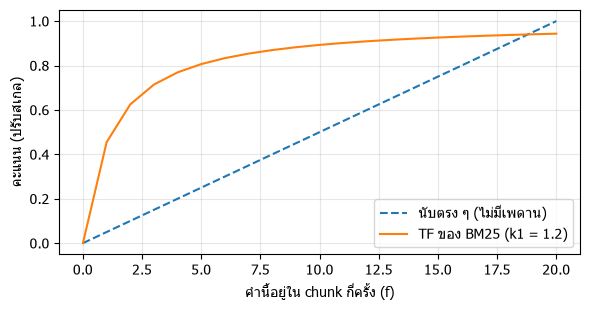

f = 1 -> 0.455   f = 2 -> 0.625   f = 10 -> 0.893


In [13]:
import matplotlib.pyplot as plt
f = np.arange(0, 21)
plt.figure(figsize=(6, 3.2))
plt.plot(f, f / f.max(), "--", label="นับตรง ๆ (ไม่มีเพดาน)")
plt.plot(f, f / (f + 1.2), label="TF ของ BM25 (k1 = 1.2)")
plt.xlabel("คำนี้อยู่ใน chunk กี่ครั้ง (f)"); plt.ylabel("คะแนน (ปรับสเกล)")
plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()
print("f = 1 ->", round(1/2.2, 3), "  f = 2 ->", round(2/3.2, 3), "  f = 10 ->", round(10/11.2, 3))

**อ่านผล:** เส้น BM25 พุ่งขึ้นเร็วช่วงแรกแล้วแบน คำที่อยู่ 10 ครั้งได้คะแนนแค่ ~2 เท่าของคำที่อยู่ 1 ครั้ง (ไม่ใช่ 10 เท่า)
เพราะเจอคำ 1-2 ครั้งก็บอกได้แล้วว่า chunk นี้พูดเรื่องนั้น การซ้ำเพิ่มไม่ได้แปลว่าเกี่ยวข้องมากขึ้นเรื่อย ๆ (กัน chunk ที่ "ยัดคำ" ชนะ)

> **ไม่ใช่ font ไทย?** ถ้าคำในกราฟเป็นสี่เหลี่ยม แปลว่า matplotlib ไม่มี font ไทย ไม่กระทบการเรียน ดูเส้นกราฟเป็นหลัก

---
## 5. Dense vs BM25 vs Hybrid (RRF)

### คืออะไร
- **Dense search:** ค้นด้วย vector (หัวข้อ 2) — เทียบความหมาย
- **Sparse / BM25 search:** ค้นด้วยคำ (หัวข้อ 3-4) — เทียบคำที่ตรงกัน
- **Hybrid search:** ค้นทั้งสองแบบแล้วรวมผลด้วย **RRF (Reciprocal Rank Fusion)**

```
RRF(chunk) = Σ ทุกระบบ  1 / (60 + อันดับในระบบนั้น)      อันดับเริ่มที่ 1
```

### ทำทำไม
ถ้าสองวิธีเก่งคนละแบบ ใช้คู่กันจะครอบคลุมกว่า (สไลด์หน้า 18 ของ Anthropic: embedding + BM25 พลาดน้อยกว่า embedding อย่างเดียว)
แต่คะแนนของสองวิธีคนละสเกล (BM25 ได้ 4.78, cosine ได้ 0.85) บวกกันตรง ๆ ไม่ได้ จึงใช้ RRF ที่ดูแค่ **อันดับ**

### ทำยังไง
1. สร้าง index เดียวที่มี 2 field: `text` (analyzer thai → ใช้กับ BM25) และ `vec` (knn_vector 1024 มิติ HNSW → ใช้กับ dense)
2. เขียน 3 ฟังก์ชัน: `bm25()` = query `match`, `dense()` = query `knn`, `rrf()` = รวมด้วยอันดับ (ทิ้งคะแนนเดิม)
3. ค้นด้วยคำถาม 3 ข้อที่ **ออกแบบให้แต่ละวิธีถนัดต่างกัน** (ชื่อเฉพาะ / ภาษาชาวบ้าน / ภาษาอังกฤษ) แล้วดูว่าใครเจอ ใครพลาด

### ทายก่อนรัน
คำถาม 3 ข้อด้านล่าง ข้อไหน BM25 จะหาไม่เจอเลย? ข้อไหน dense จะแพ้ BM25?

In [14]:
mapping_vec = {"properties": {"text": {"type": "text", "analyzer": "thai"},
                              "vec": {"type": "knn_vector", "dimension": 1024,
                                      "method": {"name": "hnsw", "space_type": "cosinesimil", "engine": "lucene"}}}}
client.indices.delete(index=INDEX)
client.indices.create(index=INDEX, body={"settings": {"index.knn": True}, "mappings": mapping_vec})
for i, (d, v) in enumerate(zip(docs, model.encode(docs, normalize_embeddings=True))):
    client.index(index=INDEX, id=str(i), body={"text": d, "vec": v.tolist()})
client.indices.refresh(index=INDEX)

def bm25(q, k=3):
    return [(int(h["_id"]), round(h["_score"], 2)) for h in
            client.search(index=INDEX, body={"size": k, "query": {"match": {"text": q}}})["hits"]["hits"]]

def dense(q, k=3):
    v = model.encode(q, normalize_embeddings=True).tolist()
    return [(int(h["_id"]), round(h["_score"], 2)) for h in
            client.search(index=INDEX, body={"size": k, "query": {"knn": {"vec": {"vector": v, "k": k}}}})["hits"]["hits"]]

def rrf(*rankings, k=60):
    scores = {}
    for ranking in rankings:
        for rank, (doc_id, _) in enumerate(ranking, 1):    # ทิ้งคะแนนเดิม ใช้แค่อันดับ
            scores[doc_id] = scores.get(doc_id, 0) + 1 / (k + rank)
    return sorted(((d, round(s, 4)) for d, s in scores.items()), key=lambda x: -x[1])

rows = []
for q in ["ยาโอเมพราโซล", "ตาพร่ามัวเหมือนมีหมอกบัง", "pregnant woman rubella"]:
    b, d = bm25(q), dense(q)
    f = rrf(b, d)
    rows.append({"คำถาม": q, "BM25 (doc, คะแนน)": b or "ไม่เจอเลย", "dense (doc, คะแนน)": d, "RRF อันดับ 1": f[0],
                 "doc อันดับ 1 ของ RRF": docs[f[0][0]][:35]})
pd.DataFrame(rows)

,คำถาม,"BM25 (doc, คะแนน)","dense (doc, คะแนน)",RRF อันดับ 1,doc อันดับ 1 ของ RRF
0,ยาโอเมพราโซล,"[(5, 4.78), (2, 1.02)]","[(5, 0.85), (4, 0.66), (3, 0.66)]","(5, 0.0328)",ยาโอเมพราโซลใช้ลดกรดในกระเพาะอาหารส
1,ตาพร่ามัวเหมือนมีหมอกบัง,ไม่เจอเลย,"[(4, 0.79), (3, 0.72), (1, 0.68)]","(4, 0.0164)",ต้อกระจกทำให้แก้วตาขุ่น มองเห็นไม่ช
2,pregnant woman rubella,ไม่เจอเลย,"[(1, 0.76), (0, 0.73), (3, 0.68)]","(1, 0.0164)",หญิงตั้งครรภ์ที่ติดเชื้อหัดเยอรมันใ


### อ่านผล
| คำถาม | BM25 | Dense | ทำไม |
|---|---|---|---|
| "ยาโอเมพราโซล" | เจอ และ **ห่างอันดับ 2 มาก** | เจอ แต่ห่างน้อย | ชื่อเฉพาะหายาก IDF สูง BM25 มั่นใจมาก; dense มองว่าทุกประโยคเป็น "เรื่องโรค" คล้าย ๆ กัน |
| "ตาพร่ามัวเหมือนมีหมอกบัง" | **ไม่เจอ** | เจอต้อกระจก | ไม่มีคำไหนตรงกับ "แก้วตาขุ่น มองเห็นไม่ชัด" แต่ความหมายเดียวกัน |
| "pregnant woman rubella" | **ไม่เจอ** | เจอ | BM25 ข้ามภาษาไม่ได้ |

สองวิธี **อ่อนคนละจุด** → ใช้คู่กัน และ RRF ได้อันดับ 1 ถูกทั้ง 3 ข้อ

### RRF คำนวณด้วยมือ
คำถาม "ยาโอเมพราโซล": doc 5 ได้อันดับ 1 ทั้งสองฝั่ง → 1/61 + 1/61 = **0.0328** (ตรงกับตาราง)
ถ้า doc ได้อันดับ 1 ฝั่งเดียว → 1/61 = 0.0164 (แค่ครึ่ง) **RRF ให้รางวัลการเห็นพ้องกัน**

ทำไม 60? ค่ามาตรฐานจากงานวิจัยต้นฉบับ ทำให้อันดับ 1 กับ 2 ต่างกันนิดเดียว (1/61 vs 1/62) ระบบเดียวชี้ขาดไม่ได้

### ลองเอง
ทายก่อน: doc ที่ได้อันดับ 1 ใน dense แต่ไม่ติด BM25 กับ doc ที่ได้อันดับ 3 ทั้งสองฝั่ง อันไหนชนะใน RRF? แล้วรันเช็ก

In [15]:
print("อันดับ 1 ฝั่งเดียว      :", round(1/61, 4))
print("อันดับ 3 ทั้งสองฝั่ง     :", round(1/63 + 1/63, 4))
client.indices.delete(index=INDEX)     # ลบ index ทดลอง ไม่ให้รกเครื่อง

อันดับ 1 ฝั่งเดียว      : 0.0164
อันดับ 3 ทั้งสองฝั่ง     : 0.0317


{'acknowledged': True}

---
## 6. RAG ทั้งวงจร (ไม่ใช้ OpenSearch ให้เห็นแก่นล้วน ๆ)

### คืออะไร
ประกอบทุกชิ้นเป็นระบบเดียว 5 ขั้น:

```
[ทำครั้งเดียว]   1. Chunking: ตัดเอกสารเป็นท่อน → 2. Embedding: แปลงทุกท่อนเป็น vector (เก็บไว้)
[ทุกคำถาม]     3. Retrieval: embed คำถาม แล้วหาท่อนที่ cosine สูงสุด
               4. Augmented: เอาท่อนที่ได้ใส่ส่วน Context ของ prompt
               5. Generation: LLM ตอบจาก Context
```

### ทำทำไม
ระบบของครูและระบบใหม่ก็คือ 5 ขั้นนี้ แค่แต่ละขั้นซับซ้อนขึ้น ถ้าเห็นโครงในรูปที่ง่ายที่สุดก่อน จะอ่านโค้ดใหญ่ออกว่าส่วนไหนคือขั้นไหน
และใช้ numpy แทน vector DB ให้เห็นว่า "vector DB" แก่นจริง ๆ คือการเก็บ vector แล้วหาตัวที่ใกล้ที่สุด

### ทำยังไง
1. ตัด 4 ไฟล์เป็นย่อหน้า (แบบง่ายที่สุด) → embed ทุกย่อหน้าครั้งเดียวเก็บไว้ในตัวแปร (แทน vector DB)
2. เขียนฟังก์ชัน `mini_rag()`: embed คำถาม → คูณเมทริกซ์หา cosine กับทุกย่อหน้า → เลือก 3 อันดับแรก → ใส่ลง prompt → ส่งให้ LLM
3. พิมพ์ prompt ที่ส่งจริงออกมาดู แล้วทดสอบกับคำถามที่มีคำตอบ และคำถามที่ไม่มีคำตอบในเอกสาร

### ขั้น 1-2: chunk และ embed ทั้ง corpus
ตัดแบบง่ายที่สุด: ตามย่อหน้า (บรรทัดว่าง) และทิ้งก้อนที่สั้นกว่า 50 ตัวอักษร (หัวข้อเปล่า ๆ)

In [16]:
chunks = []
for name, text in read_corpus().items():
    chunks += [(name, p.strip()) for p in text.split("\n\n") if len(p.strip()) > 50]
chunk_vecs = model.encode([c for _, c in chunks], normalize_embeddings=True, batch_size=16)
print(f"{len(chunks)} chunks  ->  ตาราง vector {chunk_vecs.shape}")
print("ตัวอย่าง chunk แรก:", chunks[0])

247 chunks  ->  ตาราง vector (247, 1024)
ตัวอย่าง chunk แรก: ('1.md', '# หัดเยอรมัน อาการ สาเหตุ และการรักษาโรคหัดเยอรมัน 10 วิธี !!')


### ขั้น 3-5: ถาม → ค้น → ใส่ prompt → ตอบ
เขียนเป็นฟังก์ชันเดียว แล้วพิมพ์ **prompt ที่ส่งให้ LLM จริง** ออกมาด้วย ให้เห็นว่า "Augmented" หน้าตาเป็นยังไง

In [17]:
def mini_rag(question, k=3, show_prompt=False):
    q_vec = model.encode(question, normalize_embeddings=True)       # ต้อง embed ด้วยโมเดลเดียวกัน
    scores = chunk_vecs @ q_vec                                     # cosine กับทุก chunk ในบรรทัดเดียว
    top = scores.argsort()[::-1][:k]                                # k อันดับแรก (มาก -> น้อย)
    for rank, i in enumerate(top, 1):
        print(f"#{rank} score={scores[i]:.3f} [{chunks[i][0]}] {chunks[i][1][:90]}")
    context = "\n\n".join(f"[{n}] {chunks[i][1]}" for n, i in enumerate(top, 1))
    prompt = f"""ตอบคำถามโดยใช้ข้อมูลใน Context เท่านั้น ถ้าไม่มีให้ตอบว่าไม่พบข้อมูล และอ้างอิงเลข [n]

Context:
{context}

Question: {question}"""
    if show_prompt:
        print("\n----- prompt ที่ส่งให้ LLM -----\n" + prompt[:900] + ("..." if len(prompt) > 900 else ""))
    return llm(prompt)

print("\nA:", mini_rag("ระยะฟักตัวของโรคหัดเยอรมันนานกี่วัน", show_prompt=True))

#1 score=0.703 [1.md] หัดเยอรมัน, เหือด หรือ หัดสามวัน (German measles/เจอร์มันมีเซิลส์, Rubella/รูเบลลา หรือ Th
#2 score=0.701 [1.md] ระยะฟักตัวของโรค (ตั้งแต่ได้รับเชื้อจนแสดงอาการ) : ประมาณ 12-24 วัน[1],[2],[3] โดยเฉลี่ยปร
#3 score=0.688 [1.md] - การติดเชื้อในเด็กตั้งแต่หลังคลอดเป็นต้นไปและในผู้ใหญ่ โดยประมาณ 50% ของผู้ที่ติดเชื้อหัด

----- prompt ที่ส่งให้ LLM -----
ตอบคำถามโดยใช้ข้อมูลใน Context เท่านั้น ถ้าไม่มีให้ตอบว่าไม่พบข้อมูล และอ้างอิงเลข [n]

Context:
[1] หัดเยอรมัน, เหือด หรือ หัดสามวัน (German measles/เจอร์มันมีเซิลส์, Rubella/รูเบลลา หรือ Three-day measles/ทรีเดย์มีเซิลส์) เป็นโรคไข้ออกผื่นที่เกิดจากการติดเชื้อไวรัสหัดเยอรมัน ผู้ป่วยจะมีอาการไข้และออกผื่นคล้ายโรคหัด แต่จะมีความรุนแรงและโรคแทรกซ้อนน้อยกว่าหัด โรคนี้ไม่ใช่โรคร้ายแรง ถ้าเป็นกับเด็กหรือผู้ใหญ่ทั่วไป มักจะหายได้เองโดยไม่มีโรคแทรกซ้อนที่รุนแรง แต่ถ้าเกิดในหญิงตั้งครรภ์ในช่วงไตรมาสแรกของการตั้งครรภ์ เชื้ออาจแพร่กระจายเข้าทารกในครรภ์ ทำให้ทารกพิการ แท้ง หรือตายในครรภ์ได้ และโรคนี้เมื่อเป็นแล้วผู้ป่วยมักจะมีภูม


A: ระยะฟักตัวของโรคประมาณ 12-24 วัน โดยเฉลี่ยประมาณ 16-18 วัน [2]


### อ่านผล
- คำถามเดียวกับหัวข้อ 1, LLM ตัวเดียวกัน แต่คราวนี้ **ตอบถูก (12-24 วัน เฉลี่ย 16-18) และบอกว่าเอามาจากท่อน [2]** = นี่คือนิยามของ RAG
- prompt มี 3 ส่วนที่มีเหตุผลทั้งหมด:

| ส่วน | ทำไม |
|---|---|
| "ใช้ข้อมูลใน Context เท่านั้น" | ไม่ให้เอาความรู้ที่จำมา (ซึ่งเห็นแล้วว่าผิด) มาปน |
| "ถ้าไม่มีให้ตอบว่าไม่พบข้อมูล" | ให้ทางออก ถ้าไม่บอก LLM มักพยายามตอบให้ได้ (= แต่ง) |
| "อ้างอิงเลข [n]" | ตรวจย้อนได้ ถ้าอ้าง [2] แต่ [2] ไม่มีข้อมูลนั้น = จับได้ว่าแต่ง |

- **ปัญหาที่ต้องสังเกต (จะแก้ใน Notebook 3):**
  1. ท่อนที่มีคำตอบอยู่ **อันดับ 2** แพ้ย่อหน้าแนะนำโรคไปนิดเดียว ถ้าส่งแค่ top-1 จะตอบผิด → เหตุผลของ **reranking**
  2. ท่อน #2 เขียนแค่ "ระยะฟักตัวของโรค" ไม่บอกว่าโรคอะไร ถ้ามีหลายโรค embedding แยกไม่ออก → เหตุผลของ **breadcrumb / Contextual Retrieval**

### ลองเอง: คำถามที่ไม่มีคำตอบในเอกสาร
คำถามข้อ 5 ของครู ไม่มีคำตอบในเอกสาร ระบบควรตอบว่าไม่พบข้อมูล ไม่ใช่แต่ง

In [18]:
print("A:", mini_rag("โรคหัดเยอรมันมีผลกระทบอย่างไรต่อระบบสาธารณสุขและเศรษฐกิจของประเทศ?"))

#1 score=0.588 [1.md] หัดเยอรมัน, เหือด หรือ หัดสามวัน (German measles/เจอร์มันมีเซิลส์, Rubella/รูเบลลา หรือ Th
#2 score=0.580 [1.md] กลไกการเกิดโรค : เมื่อผู้ป่วยได้รับเชื้อหัดเยอรมันเข้าสู่ระบบทางเดินหายใจแล้ว เชื้อนี้จะกร
#3 score=0.574 [1.md] หัดเยอรมัน* เป็นโรคที่พบได้บ่อยทั้งในเด็กและผู้ใหญ่ พบอัตราป่วยสูงสุดในช่วงอายุ 15-24 ปี ส


A: ไม่พบข้อมูล


**อ่านผล:** ท่อนที่ค้นได้พูดเรื่องหัดเยอรมันจริง แต่ไม่มีเรื่องเศรษฐกิจ ถ้า LLM ทำตาม prompt จะบอกว่าไม่พบข้อมูล
ถ้ามันยังแต่ง = ปัญหาอยู่ที่ Generation ไม่ใช่ Retrieval (ครูพูดว่า "ค้นมาถูกแต่สรุปผิด โมเดลไม่ควรอยู่ต่อ")

---
## สรุป Notebook 1

| ชิ้นส่วน | เก่ง | อ่อน |
|---|---|---|
| Embedding / dense | ความหมาย, ภาษาชาวบ้าน, ข้ามภาษา | ชื่อเฉพาะ, ตัวเลข, ข้อความยาวหลายเรื่อง |
| Inverted index / BM25 | ชื่อเฉพาะ, คำที่ตรงกัน | คำพ้อง, ข้ามภาษา, **พังถ้า analyzer ตัดคำผิด** |
| RRF | รวมสองวิธีโดยไม่สนสเกลคะแนน | รวมได้แค่ของที่สองวิธีหามาได้ |
| RAG ทั้งวงจร | ตอบจากเอกสาร อ้างอิงได้ | **ค้นผิด = ตอบผิด** |

**ต่อไป:** Notebook 2 เอาความรู้นี้ไปส่องระบบของครู แล้วหาว่าอ่อนตรงไหน พร้อมหลักฐาน